# From PCA to Deep Auto-encoders with Keras

An auto-encoder compresses its input into a small code (the encoder), then rebuilds it from that code (the decoder): its target is its own input. This notebook trains several of them on MNIST (60,000 training and 10,000 test images of handwritten digits, 28 × 28 in grayscale), from the simplest to the deepest:

1. A linear auto-encoder
2. The linear auto-encoder against PCA
3. A deep auto-encoder
4. The latent space
5. Anomaly detection
6. The code size
7. Going further: a sparse auto-encoder

Each part reuses the models of the previous ones; the last one is optional. No GPU needed: the notebook runs in about twenty minutes on a CPU, half of it for part 6, which trains six auto-encoders.

(60000, 784) (10000, 784)


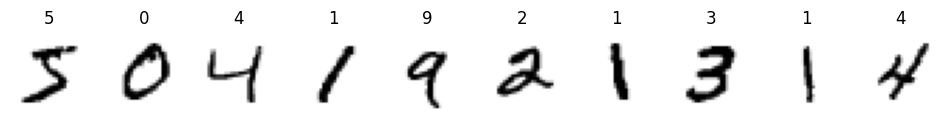

In [1]:
import keras
import matplotlib.pyplot as plt
import numpy as np
from keras import layers
from sklearn.decomposition import PCA

keras.utils.set_random_seed(0)

(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()
input_dim = 28 * 28
# Pixels in [0, 1], like a sigmoid's output: neither centered nor scaled
X_train = X_train.reshape(-1, input_dim) / 255
X_test = X_test.reshape(-1, input_dim) / 255
print(X_train.shape, X_test.shape)


def show_images(*rows: np.ndarray, titles: list | np.ndarray | None = None) -> None:
  # Shows rows of 28 × 28 images, one row per array
  n = len(rows[0])
  _, axes = plt.subplots(
    len(rows), n, figsize=(n * 1.2, len(rows) * 1.3), squeeze=False
  )
  for row, images in zip(axes, rows):
    for ax, image in zip(row, images):
      ax.imshow(np.reshape(image, (28, 28)), cmap="gray_r")
      ax.axis("off")
  for ax, title in zip(axes[0], [] if titles is None else titles):
    ax.set_title(title)
  plt.show()


show_images(X_train[:10], titles=y_train[:10])

## 1. A linear auto-encoder

Without an activation function, the encoder and the decoder are only linear maps (plus a bias). The model follows the "Auto-encoder in Keras" slide, but without activations:

- `encoder`: a `Dense` layer of `encoding_dim = 20` units, on inputs of size `input_dim`;
- `decoder`: a `Dense` layer of `input_dim` units, on codes of size `encoding_dim`;
- `autoencoder`, which chains the two, compiled with the Adam optimizer and the `"mse"` loss.

A model can serve as a layer of another one: `encoder` and `decoder` stay usable on their own, which the next parts make use of.

In [2]:
encoding_dim = 20
encoder = keras.Sequential(
  [keras.Input(shape=(input_dim,)), layers.Dense(encoding_dim)], name="encoder"
)
decoder = keras.Sequential(
  [keras.Input(shape=(encoding_dim,)), layers.Dense(input_dim)], name="decoder"
)
autoencoder = keras.Sequential([encoder, decoder], name="autoencoder")
autoencoder.compile(optimizer="adam", loss="mse")
autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder (Sequential)            │ (None, 20)             │        15,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Sequential)            │ (None, 784)            │        16,464 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,164 (125.64 KB)

 Trainable params: 32,164 (125.64 KB)

 Non-trainable params: 0 (0.00 B)

### Training

The target is the input: `fit(X_train, X_train)`. The validation loss is computed on the test images.

Epoch 1/10
235/235 - 4s - 16ms/step - loss: 0.0488 - val_loss: 0.0301
Epoch 2/10
235/235 - 3s - 11ms/step - loss: 0.0272 - val_loss: 0.0248
Epoch 3/10
235/235 - 3s - 11ms/step - loss: 0.0247 - val_loss: 0.0240
Epoch 4/10
235/235 - 2s - 10ms/step - loss: 0.0244 - val_loss: 0.0238
Epoch 5/10
235/235 - 1s - 6ms/step - loss: 0.0242 - val_loss: 0.0238
Epoch 6/10
235/235 - 1s - 6ms/step - loss: 0.0242 - val_loss: 0.0237
Epoch 7/10
235/235 - 1s - 6ms/step - loss: 0.0241 - val_loss: 0.0237
Epoch 8/10
235/235 - 1s - 5ms/step - loss: 0.0241 - val_loss: 0.0237
Epoch 9/10
235/235 - 1s - 5ms/step - loss: 0.0241 - val_loss: 0.0237
Epoch 10/10
235/235 - 1s - 6ms/step - loss: 0.0241 - val_loss: 0.0236


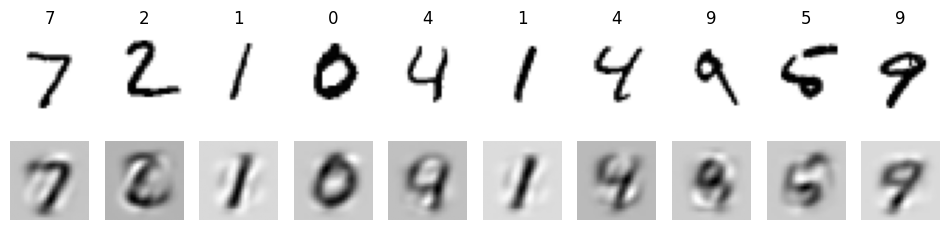

In [3]:
autoencoder.fit(
  X_train,
  X_train,
  epochs=10,
  batch_size=256,
  validation_data=(X_test, X_test),
  verbose=2,
)
linear_decoder = decoder  # kept for part 2
X_test_linear = autoencoder.predict(X_test, verbose=0)
show_images(X_test[:10], X_test_linear[:10], titles=y_test[:10])

The reconstructions are blurry, on a gray background, but most digits stay recognizable: 20 numbers keep their overall shape. The gray background comes from the linear output, which returns pixels a little off 0 everywhere. Some digits drift towards another one, like the first 4, which looks like a 9: the linear auto-encoder only keeps the data's main trends.

## 2. The linear auto-encoder against PCA

The "Linear auto-encoder and PCA" slide states it: trained with the MSE, a linear auto-encoder with a code of size k finds the subspace of PCA's first k components, but not its axes. Let's check it with three measures:

- a `PCA` with `encoding_dim` components, fitted on `X_train`, rebuilds `X_test`: we compare the mean squared error of its reconstruction with the auto-encoder's;
- the decoder's 20 directions are the rows of its kernel `W` (20 × 784): for each one, we measure the share of its norm that lies in PCA's subspace (1: entirely inside);
- finally, the largest absolute cosine between two directions of the decoder, then between two components of PCA (0: orthogonal).

In [4]:
pca = PCA(encoding_dim).fit(X_train)
X_test_pca = pca.inverse_transform(pca.transform(X_test))
pca_error = np.mean((X_test - X_test_pca) ** 2)
linear_error = np.mean((X_test - X_test_linear) ** 2)
print(f"Error: PCA {pca_error:.4f}, linear AE {linear_error:.4f}")

W = linear_decoder.layers[0].get_weights()[0]  # (20, 784)
share = np.linalg.norm(W @ pca.components_.T, axis=1) / np.linalg.norm(W, axis=1)
print(f"Share in PCA's subspace: from {share.min():.3f} to {share.max():.3f}")


def max_cosine(V: np.ndarray) -> float:
  V = V / np.linalg.norm(V, axis=1, keepdims=True)
  cosines = V @ V.T
  return np.abs(cosines[~np.eye(len(V), dtype=bool)]).max()


print(
  f"Largest cosine: decoder {max_cosine(W):.2f}, PCA {max_cosine(pca.components_):.2f}"
)

Error: PCA 0.0235, linear AE 0.0236
Share in PCA's subspace: from 0.969 to 1.000
Largest cosine: decoder 0.23, PCA 0.00


The two errors are nearly equal: the linear auto-encoder does as well as PCA, but no better, since PCA gives the best possible linear reconstruction with 20 dimensions. Its 20 directions lie almost entirely in PCA's subspace (over 95%): it found the same subspace, up to the training's inaccuracies. But they aren't orthogonal (the largest cosine is about 0.2, against 0 for PCA), nor sorted by explained variance: nothing in the loss requires it. PCA gives that basis on top, and without any training.

## 3. A deep auto-encoder

Let's add a nonlinear hidden layer on each side of the code, as on the "Auto-encoder in Keras" slide:

- `encoder`: a `Dense` of 128 units, then one of `encoding_dim` units, both with the ReLU activation;
- `decoder`: a `Dense` of 128 units (ReLU), then the output layer, of `input_dim` units, with a sigmoid: it returns values in ]0, 1[, like the pixels, whereas a linear output could leave that range;
- `autoencoder`, which chains the two, with the `"binary_crossentropy"` loss, which treats each target pixel as a probability (`"mse"` would work too).

We train it, then compare its error with PCA's and the linear auto-encoder's.

In [5]:
encoder = keras.Sequential(
  [
    keras.Input(shape=(input_dim,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(encoding_dim, activation="relu"),
  ],
  name="encoder",
)
decoder = keras.Sequential(
  [
    keras.Input(shape=(encoding_dim,)),
    layers.Dense(128, activation="relu"),
    # Output in ]0, 1[, like the pixels
    layers.Dense(input_dim, activation="sigmoid"),
  ],
  name="decoder",
)
autoencoder = keras.Sequential([encoder, decoder], name="autoencoder")
# Each target pixel, in [0, 1], is treated as a probability
autoencoder.compile(optimizer="adam", loss="binary_crossentropy")
autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder (Sequential)            │ (None, 20)             │       103,060 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Sequential)            │ (None, 784)            │       103,824 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 206,884 (808.14 KB)

 Trainable params: 206,884 (808.14 KB)

 Non-trainable params: 0 (0.00 B)

### Training and comparison

Epoch 1/20
235/235 - 5s - 22ms/step - loss: 0.2495 - val_loss: 0.1697
Epoch 2/20
235/235 - 3s - 12ms/step - loss: 0.1540 - val_loss: 0.1377
Epoch 3/20
235/235 - 5s - 23ms/step - loss: 0.1311 - val_loss: 0.1239
Epoch 4/20
235/235 - 3s - 14ms/step - loss: 0.1230 - val_loss: 0.1196
Epoch 5/20
235/235 - 4s - 17ms/step - loss: 0.1196 - val_loss: 0.1171
Epoch 6/20
235/235 - 6s - 24ms/step - loss: 0.1172 - val_loss: 0.1150
Epoch 7/20
235/235 - 6s - 25ms/step - loss: 0.1154 - val_loss: 0.1133
Epoch 8/20
235/235 - 10s - 44ms/step - loss: 0.1139 - val_loss: 0.1120
Epoch 9/20
235/235 - 9s - 40ms/step - loss: 0.1127 - val_loss: 0.1109
Epoch 10/20
235/235 - 5s - 22ms/step - loss: 0.1115 - val_loss: 0.1096
Epoch 11/20
235/235 - 6s - 24ms/step - loss: 0.1097 - val_loss: 0.1078
Epoch 12/20
235/235 - 6s - 24ms/step - loss: 0.1083 - val_loss: 0.1067
Epoch 13/20
235/235 - 6s - 24ms/step - loss: 0.1073 - val_loss: 0.1056
Epoch 14/20
235/235 - 5s - 23ms/step - loss: 0.1057 - val_loss: 0.1040
Epoch 15/20
23

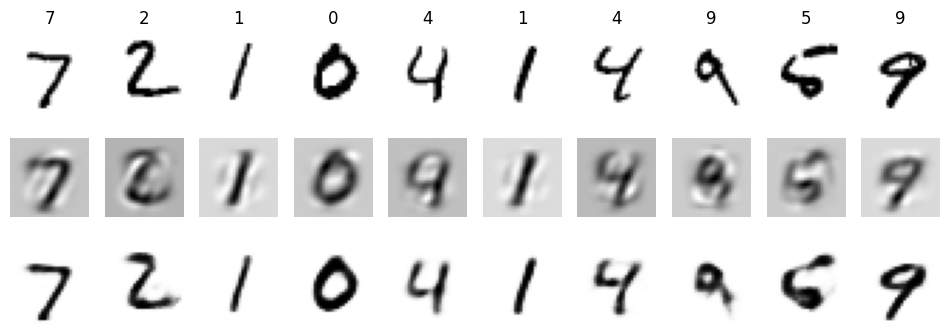

In [6]:
autoencoder.fit(
  X_train,
  X_train,
  epochs=20,
  batch_size=256,
  validation_data=(X_test, X_test),
  verbose=2,
)
X_test_pred = autoencoder.predict(X_test, verbose=0)
deep_error = np.mean((X_test - X_test_pred) ** 2)
print(
  f"Mean squared error: PCA {pca_error:.4f}, "
  f"linear AE {linear_error:.4f}, deep AE {deep_error:.4f}"
)
# Top: the originals, then the linear AE, then the deep AE
show_images(X_test[:10], X_test_linear[:10], X_test_pred[:10], titles=y_test[:10])

With the same code of 20 numbers, the deep auto-encoder rebuilds clearly better than PCA and the linear auto-encoder: its nonlinear layers follow curved surfaces, out of a subspace's reach.

## 4. The latent space

The encoder alone turns each test image into its code, a point of a space with `encoding_dim` dimensions: the latent space.

In [7]:
codes = encoder.predict(X_test, verbose=0)
print(codes.shape)

(10000, 20)


### Where do the codes live?

Could the decoder alone make new digits from random codes? Let's first look at where the real codes live: for each of the 20 dimensions, the minimum, the mean and the maximum of `codes`, and the number of dead dimensions, 0 for every image. Then let's decode 10 white noise codes, drawn uniformly in [0, 1] on each dimension (top), and 10 codes drawn uniformly between each dimension's minimum and maximum (bottom).

Min: [0.  0.  0.  0.8 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
 0.  0. ]
Mean: [13.   6.3 15.8 25.4 10.2 12.5 14.8  7.7  6.8 10.3  8.9  2.2 16.4  0.
 14.2  8.  10.9 17.1  8.3 14.7]
Max: [30.3 21.4 45.6 60.6 26.5 36.3 34.4 20.5 18.8 29.  21.   9.1 46.5  0.
 34.4 18.  25.8 39.4 20.5 34.7]
Dead dimensions: 1


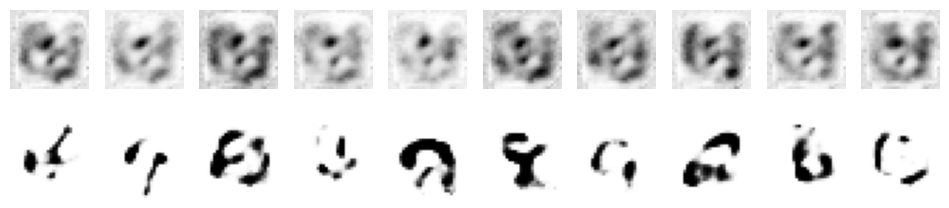

In [8]:
low, high = codes.min(axis=0), codes.max(axis=0)
print("Min:", np.round(low, 1))
print("Mean:", np.round(codes.mean(axis=0), 1))
print("Max:", np.round(high, 1))
print("Dead dimensions:", int((high == 0).sum()))

rng = np.random.default_rng(0)
white_noise = rng.uniform(0, 1, size=(10, encoding_dim))
in_range = rng.uniform(low, high, size=(10, encoding_dim))
# Top: white noise, bottom: codes drawn in their range
show_images(
  decoder.predict(white_noise, verbose=0), decoder.predict(in_range, verbose=0)
)

The codes don't look like uniform noise in [0, 1]: the ReLU makes them positive or zero, their range changes from one dimension to the next and reaches several tens, and one dimension or more may be dead, zero for every image. White noise thus falls into a corner of the latent space, near the origin, that the decoder has almost never seen: it returns blots that all look alike. Drawn in their range, the codes do no better: the real codes take up only a small part of that box, as their dimensions are tied together. An auto-encoder compresses, but doesn't generate: its decoder can only decode the codes the encoder produces. The variational auto-encoder, in the next notebook, forces the codes to follow a known distribution, $\mathcal{N}(0, I)$, from which one can draw.

### The digits' centroids

The codes aren't scattered at random: those of the same digit cluster together. The mean code of each digit, its centroid, once decoded, gives a typical image of it.

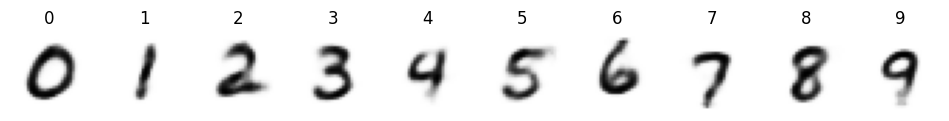

In [9]:
centroids = np.stack([codes[y_test == digit].mean(axis=0) for digit in range(10)])
show_images(decoder.predict(centroids, verbose=0), titles=list(range(10)))

Each decoded centroid gives a sharp, typical digit, smoother than the real ones: averaging the codes erases each handwriting's quirks.

### Interpolating between two centroids

Codes evenly spaced on the segment between two centroids, once decoded, show how the decoder goes from one digit to the other. Other pairs can be tried by changing `latent_walk`'s arguments.

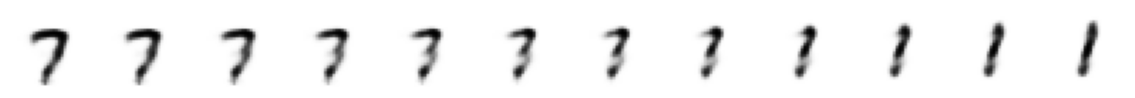

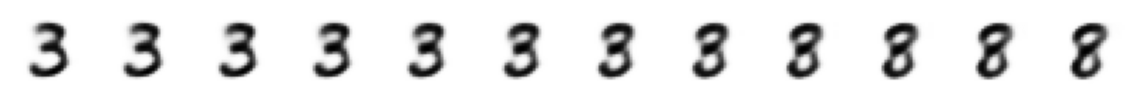

In [10]:
def latent_walk(start: int, end: int, n: int = 12) -> None:
  # n evenly spaced codes, from start's centroid to end's
  walk = np.linspace(centroids[start], centroids[end], n)
  show_images(decoder.predict(walk, verbose=0))


latent_walk(7, 1)
latent_walk(3, 8)

The 7 straightens up and loses its bar to become a 1, the 3 closes on the left to become an 8: from one centroid to the other, the decoder goes through intermediate shapes, without jumps. Close codes decode into close images.

## 5. Anomaly detection

An auto-encoder rebuilds well what looks like its training examples, and badly the rest (the "Anomaly detection by reconstruction error" slide). The next cell also rebuilds the training images, into `X_train_pred`; the test ones are in `X_test_pred`. Then:

- the mean squared reconstruction error of each image, into `train_errors` and `test_errors`;
- a threshold at the 99% quantile of `train_errors`: by construction, 1% of the training images are above it, and we count the test images above it;
- the 10 worst rebuilt test images, above their reconstruction, then the 10 best rebuilt ones.

In [11]:
X_train_pred = autoencoder.predict(X_train, verbose=0)

Threshold: 0.0353, 81 test images above
The worst reconstructions


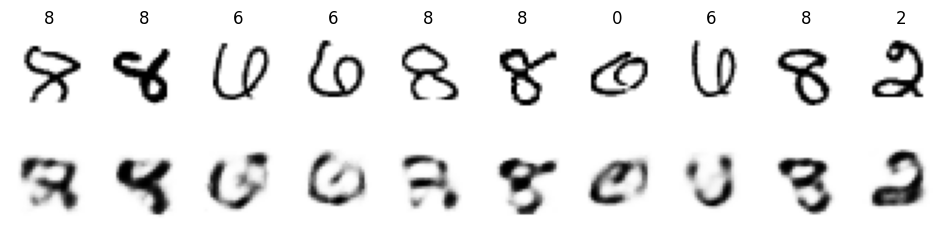

The best ones


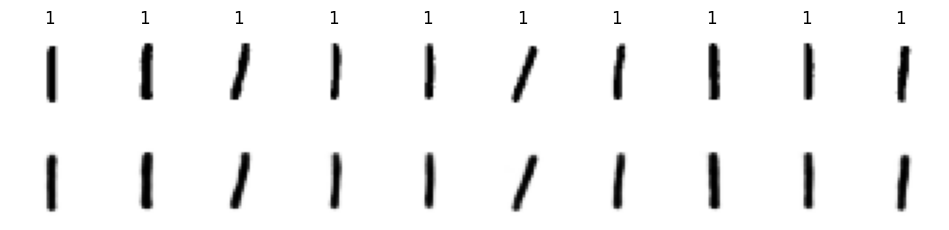

In [12]:
train_errors = np.mean((X_train - X_train_pred) ** 2, axis=1)
test_errors = np.mean((X_test - X_test_pred) ** 2, axis=1)
threshold = np.quantile(train_errors, 0.99)
print(
  f"Threshold: {threshold:.4f}, {(test_errors > threshold).sum()} test images above"
)

order = np.argsort(test_errors)
worst, best = order[::-1][:10], order[:10]
print("The worst reconstructions")
show_images(X_test[worst], X_test_pred[worst], titles=y_test[worst])
print("The best ones")
show_images(X_test[best], X_test_pred[best], titles=y_test[best])

About 1% of the test images exceed the threshold, as expected when the test set looks like the training set. The worst reconstructions are digits of a rare shape, mostly 8s and 6s with unusual loops: they stray from what the auto-encoder has seen, and its reconstruction pulls them towards a more common digit. The best ones are nearly all 1s: few lit pixels, a simple shape, hence little error. So the error also depends on the class: with a single threshold, a complicated digit is flagged more often than a 1.

## 6. The code size

A larger code rebuilds better, but compresses less. To measure that trade-off, `build_autoencoder(encoding_dim)` builds and compiles part 3's deep auto-encoder for a given code size, and the loop trains one for each code size of 2, 4, 8, 16, 32 and 64, for 10 epochs each. Each trained model is kept in the dictionary `autoencoders` (part 7 reuses the one of size 64), its last validation loss in `val_losses`. The curve has a base-2 logarithmic x axis. This cell takes half of the demo's time.

Code size 2 (compression 392x): validation loss 0.2043
Code size 4 (compression 196x): validation loss 0.1647
Code size 8 (compression 98x): validation loss 0.1434
Code size 16 (compression 49x): validation loss 0.1111
Code size 32 (compression 24x): validation loss 0.0900
Code size 64 (compression 12x): validation loss 0.0833


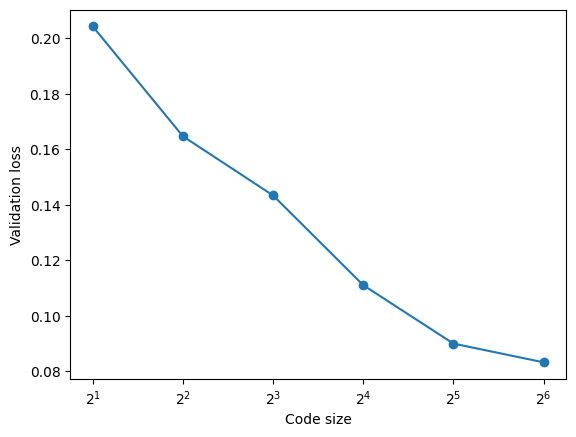

In [13]:
def build_autoencoder(encoding_dim: int) -> keras.Model:
  encoder = keras.Sequential(
    [
      keras.Input(shape=(input_dim,)),
      layers.Dense(128, activation="relu"),
      layers.Dense(encoding_dim, activation="relu"),
    ],
    name="encoder",
  )
  decoder = keras.Sequential(
    [
      keras.Input(shape=(encoding_dim,)),
      layers.Dense(128, activation="relu"),
      layers.Dense(input_dim, activation="sigmoid"),
    ],
    name="decoder",
  )
  autoencoder = keras.Sequential([encoder, decoder], name="autoencoder")
  autoencoder.compile(optimizer="adam", loss="binary_crossentropy")
  return autoencoder


autoencoders, val_losses = {}, {}
for size in [2, 4, 8, 16, 32, 64]:
  autoencoders[size] = build_autoencoder(size)
  history = autoencoders[size].fit(
    X_train,
    X_train,
    epochs=10,
    batch_size=256,
    validation_data=(X_test, X_test),
    verbose=0,
  )
  val_losses[size] = history.history["val_loss"][-1]
  print(
    f"Code size {size} (compression {input_dim / size:.0f}x): "
    f"validation loss {val_losses[size]:.4f}"
  )

plt.plot(list(val_losses), list(val_losses.values()), marker="o")
plt.xscale("log", base=2)
plt.xlabel("Code size")
plt.ylabel("Validation loss")
plt.show()

The loss drops fast while the code is very small, then less and less: beyond about thirty dimensions, enlarging the code hardly improves the reconstruction anymore. A code of 16 to 32 dimensions is a good trade-off, that is a compression ratio of 784 / 32 = 24.5 to 784 / 16 = 49 (in number of values: the code and the pixels are all floats).

## 7. Going further: a sparse auto-encoder

A sparse auto-encoder has a large code, but a penalty on its activations leaves only a few of them active for each image (the "Sparse auto-encoders" slide). `sparse_autoencoder` is the deep auto-encoder with a code of 64 units, whose layer adds to the loss an L1 penalty of coefficient 1e-3 on its activations (`activity_regularizer`): 1e-3 times the sum of the absolute values of its outputs. It trains for 10 epochs, like part 6's.

We compare it with part 6's auto-encoder with a 64-unit code, `autoencoders[64]`: the mean number of active (> 0) code units per test image, the number of units never active, and the mean squared reconstruction error.

In [14]:
sparse_encoder = keras.Sequential(
  [
    keras.Input(shape=(input_dim,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(
      64, activation="relu", activity_regularizer=keras.regularizers.L1(1e-3)
    ),
  ],
  name="sparse_encoder",
)
sparse_decoder = keras.Sequential(
  [
    keras.Input(shape=(64,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(input_dim, activation="sigmoid"),
  ],
  name="sparse_decoder",
)
sparse_autoencoder = keras.Sequential(
  [sparse_encoder, sparse_decoder], name="sparse_autoencoder"
)
sparse_autoencoder.compile(optimizer="adam", loss="binary_crossentropy")
sparse_autoencoder.fit(
  X_train,
  X_train,
  epochs=10,
  batch_size=256,
  validation_data=(X_test, X_test),
  verbose=0,
)

for name, model in [("No penalty", autoencoders[64]), ("L1", sparse_autoencoder)]:
  codes = model.layers[0].predict(X_test, verbose=0)
  error = np.mean((X_test - model.predict(X_test, verbose=0)) ** 2)
  print(
    f"{name}: {(codes > 0).sum(axis=1).mean():.1f} active units per image out of 64, "
    f"{(codes.max(axis=0) == 0).sum()} never active, error {error:.4f}"
  )

No penalty: 54.2 active units per image out of 64, 7 never active, error 0.0071
L1: 23.5 active units per image out of 64, 33 never active, error 0.0125


With the penalty, each image activates only about twenty code units instead of about fifty, and half of the units are never active: the penalty switches off the least useful units. Sparsity is paid for in reconstruction, whose error nearly doubles. The coefficient sets that trade-off: at 1e-4, the effect is barely visible; larger, the code ends up switched off. In a sparse code, each active unit carries a pattern one can look at on its own: that is what serves to interpret the representations of large language models.

## Key takeaways

- An auto-encoder learns to rebuild its input through a narrow code: `fit(X, X)`, with no labels.
- Linear and trained with the MSE, it finds PCA's subspace, but not its orthogonal, sorted axes: PCA gives that result better, with no training.
- Nonlinear layers rebuild much better with the same 20-number code.
- The codes take up only a small region of the latent space: decoding a random code doesn't give a digit. Generating takes a variational auto-encoder (next demo).
- The reconstruction error flags unusual images, but also depends on the class: a single threshold flags complicated digits more often.
- The code size sets the trade-off between compression and quality; an L1 penalty makes the code sparse, at the cost of a worse reconstruction.